# Opdrachten - logistic regression - Oplossing

Logistische regressie is een bijzonder populaire classificatietechniek. Enerzijds door zijn eenvoud en relatief lage eisen die het stelt in termen van rekenkracht. In veel gevallen is de performantie qua accuracy vergelijkbaar (en soms beter) dan gecompliceerdere algoritmes zoals de support vector machines.
Daarnaast heeft logistische regressie het voordeel dat het getrainde model een voorspelling doet in termen van de kans dat de input tot een bepaalde klasse behoort. Uit deze kans kan je afleiden hoe overtuigd het model is van de gemaakte voorspelling.

Het is de bedoeling om via enkele classificatieopdrachten inzicht te verkrijgen in:
- Correct trainen en het uitvoeren van hyperparameter tuning bij logistische regressie.
- Classificaties kunnen uitvoeren via logistische regressie.
- Feature engineering uitvoeren.
- Interpreteren van de verschillende performance metrics: accuracy, recall, precision, f1-score, ROC.
- Weten wanneer je te maken hebt met overfitting en underfitting en de juiste bijstellingen kunnen doen.


In [20]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn import preprocessing
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression
import seaborn as sns

## Opdracht 1: Classificatie van wijn

Het doel van deze classificatie is te kunnen achterhalen op basis van chemische parameters van welke wijnboer (cultivar) een wijn afkomstig is.

Gebruik hiervoor de dataset *wine_data.csv*. De features bevinden zich in de eerste kolommen van de dataset. De targets/outputs zijn in de laatste kolom te vinden.

### Inlezen van de dataset en vooranalyse

In [21]:
# inlezen van de data
dataset = pd.read_csv('../DATA/wine_data.csv')
dataset.head(10)

,inputs Alcohol,MalicAcid,Ash,AlcalinityOfAsh,Magnesium,TotalPhenols,flavanoids,NonflavanoidsPhenols,Proanthocyanins,ColorIntensity,Hue,OD280/OD315,Proline,Cultivar
0,12.08,1.33,2.30,23.6,70,2.20,1.59,0.42,1.38,1.74,1.07,3.21,625,1
1,12.08,1.13,2.51,24.0,78,2.00,1.58,0.40,1.40,2.20,1.31,2.72,630,1
2,12.37,1.17,1.92,19.6,78,2.11,2.00,0.27,1.04,4.68,1.12,3.48,510,1
3,13.11,1.01,1.70,15.0,78,2.98,3.18,0.26,2.28,5.30,1.12,3.18,502,1
4,12.04,4.30,2.38,22.0,80,2.10,1.75,0.42,1.35,2.60,0.79,2.57,580,1
5,12.25,1.73,2.12,19.0,80,1.65,2.03,0.37,1.63,3.40,1.00,3.17,510,1
6,12.69,1.53,2.26,20.7,80,1.38,1.46,0.58,1.62,3.05,0.96,2.06,495,1
7,12.77,3.43,1.98,16.0,80,1.63,1.25,0.43,0.83,3.40,0.70,2.12,372,1
8,13.88,5.04,2.23,20.0,80,0.98,0.34,0.40,0.68,4.90,0.58,1.33,415,2
9,12.08,1.83,2.32,18.5,81,1.60,1.50,0.52,1.64,2.40,1.08,2.27,480,1


In [22]:
dataset.shape

(178, 14)

**TAAK: Bepaal het aantal klasses. Met andere woorden, hoeveel verschillende wijnboeren zijn er?**

In [23]:
klasses = dataset.Cultivar.unique()
print('De verschillende labels:',klasses)
print('Aantal verschillende klasses: ',len(klasses))

De verschillende labels: [1 2 0]
Aantal verschillende klasses:  3


**TAAK: Hoeveel wijnen van elke wijnboer steken in de dataset? Is de dataset gebalanceerd?**<p> Gebalanceerd wil zeggen dat elke klasse ongeveer even sterk in de dataset aanwezig is.</p>

In [24]:
g= dataset.groupby('Cultivar')
g.Cultivar.count()

Cultivar
0    59
1    71
2    48
Name: Cultivar, dtype: int64

**TAAK: Bepaal de statistische kerngetallen van de verschillende features en targets.**<p> Gebruik hiervoor de *describe* functie. Gebruik de resultaten om na te gaan of er mogelijks ontbrekende waarden, uitschieters of onrealistische waarden zijn.</p>

In [25]:
dataset.describe()

,inputs Alcohol,MalicAcid,Ash,AlcalinityOfAsh,Magnesium,TotalPhenols,flavanoids,NonflavanoidsPhenols,Proanthocyanins,ColorIntensity,Hue,OD280/OD315,Proline,Cultivar
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


### Preprocessing en opsplitsen van de dataset

**TAAK: Splits de dataset in features en targets**

In [26]:
features=list(dataset.columns[:13])
print(features)
X = dataset[features].values
y = dataset['Cultivar'].values

['inputs Alcohol', 'MalicAcid', 'Ash', 'AlcalinityOfAsh', 'Magnesium', 'TotalPhenols', 'flavanoids', 'NonflavanoidsPhenols', 'Proanthocyanins', 'ColorIntensity', 'Hue', 'OD280/OD315', 'Proline']


**TAAK: Creëer een trainingset en een testset**. <p>Zorg dat je 70 wijnen in de test set zitten hebt. Gebruik hiervoor train_test_split functie.# </p>

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 70, random_state = 123)
print(X_test.shape)

(70, 13)


**TAAK: Normaliseer de dataset**. <p>Zorg er dus voor dat de features op een gelijke schaalverdeling staan. Voor het normaliseren kan gebruik gemaakt worden van de *preprocessing.StandardScaler()*. </p> 

In [28]:
# Standardscaler
scaler = preprocessing.StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

## Robustscaler
#scaler = preprocessing.RobustScaler()
#scaler.fit(X_train)
#X_train = scaler.transform(X_train)
#X_test = scaler.transform(X_test)

## MinMaxscaler
#scaler = preprocessing.MinMaxScaler()
#scaler.fit(X_train)
#X_train = scaler.transform(X_train)
#X_test = scaler.transform(X_test)


### Trainen van een logistic regression classifier en testen van het bekomen model

**TAAK: Train een logistic regression classifier op de training data.** <p>(http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)  
Kies C=1 als startwaarde. </p>

Test het getrainde model op de test set. Bepaal hierbij de confusion matrix, de accuracy en het classification report. Wat zijn de bevindingen?

Probeer indien nodig de performantie van de classifier te verhogen door de parameter C  aan te passen, class_weight aan te passen of een andere solver toe te passen. 
Schrijf de conclusies neer. 

In [29]:
logreg = linear_model.LogisticRegression(C=1,solver='liblinear',multi_class='auto')

logreg.fit(X_train,y_train)

y_pred = logreg.predict(X_test)
print(y_pred)

print(classification_report(y_test,y_pred))

print(accuracy_score(y_test,y_pred)*100)

print(confusion_matrix(y_test,y_pred))

[0 0 0 2 2 0 1 0 2 2 2 2 0 1 1 0 1 2 1 1 0 2 0 2 0 0 0 2 1 1 1 1 1 0 2 0 0
 2 2 0 0 2 1 1 1 1 1 1 1 1 2 0 1 2 1 2 0 2 2 1 1 2 0 1 1 1 1 2 0 1]
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        20
           1       1.00      0.90      0.95        31
           2       0.90      1.00      0.95        19

    accuracy                           0.96        70
   macro avg       0.95      0.97      0.96        70
weighted avg       0.96      0.96      0.96        70

95.71428571428572
[[20  0  0]
 [ 1 28  2]
 [ 0  0 19]]


Er zijn 3 verkeerd geclassificeerde wijnen. 1 wijn behoort tot wijnboer 1 maar werd als afkomstig van wijnboer 0 geclassificeerd. 2 wijnen behoren ook tot wijnboer 1 maar werden als zijnde van wijnboer 2 geclassificeerd.

**TAAK: Voorspel aan de hand van het getrainde model**

Voorspel van welke wijnboer een wijn afkomstig is met volgende samenstelling:

inputs Alcohol: 13.52 - 
MalicAcid: 2.05 - 
Ash: 2.20 - 
AlcalinityOfAsh: 17.3 - 
Magnesium: 120 - 
TotalPhenols: 2.60 - 
flavanoids: 3.52 - 
NonflavanoidsPhenols: 0.30 - 
Proanthocyanins: 2.28 - 
ColorIntensity: 7.80 - 
Hue: 0.77 - 
OD280/OD315: 2.90 - 
Proline: 862


Geef ook de overtuiging van het model weer dat de wijn van die bepaalde wijnboer afkomstig is.

In [30]:
wine = np.array([[13.52, 2.05, 2.20, 17.3, 120, 2.60, 3.52, 0.30, 2.28, 7.80, 0.77, 2.90, 862 ]])

wine = scaler.transform(wine)

print('wijboer = ', logreg.predict(wine))
print('overtuiging van het model', logreg.predict_proba(wine))

wijboer =  [0]
overtuiging van het model [[0.88181617 0.01765881 0.10052503]]


**Conclusie:** De wijn wordt met 88,18% zekerheid geclassificeerd als zijnde afkomstig van wijnboer 0.

**TAAK: Voeg extra features toe: kijk of je een beter resultaat kan bekomen via polynomiale regressie**
<p>Bepaal opnieuw alle metrics en vergelijk.  Kijk welke regularisatie het beste resultaat geeft.</p>

In [31]:
dataset = pd.read_csv('../DATA/wine_data.csv')
dataset.head(10)

# Toevoegen van extra features
features=list(dataset.columns[:13])
X = dataset[features].values
y = dataset['Cultivar'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 70, random_state = 123)

In [32]:
# Standardscaler
scaler = preprocessing.StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [33]:
# Aanmaken van de hogere orde features
graad = 4

poly = PolynomialFeatures(graad)
poly.fit(X_train)
X_train_poly = poly.transform(X_train)
X_test_poly = poly.transform(X_test)
print('dimensie van X_train_poly: ',X_train_poly.shape)
print('dimensie van X_test_poly: ',X_test_poly.shape)

dimensie van X_train_poly:  (108, 2380)
dimensie van X_test_poly:  (70, 2380)


In [34]:
# Aanmaken van het model
logreg_poly = linear_model.LogisticRegression(penalty='l1',C=1,solver='liblinear',multi_class='auto')

# Fitten van het model
logreg_poly.fit(X_train_poly,y_train)

# Predicties met het model
y_pred_poly = logreg_poly.predict(X_test_poly)
y_pred_train_poly = logreg_poly.predict(X_train_poly)

In [35]:
# Metrics
print(classification_report(y_test,y_pred_poly))

print(confusion_matrix(y_test,y_pred_poly),'\n')

print('accuracy op de test set:', accuracy_score(y_test,y_pred_poly)*100)

print('accuracy op de training set:', accuracy_score(y_pred_train_poly,logreg_poly.predict(X_train_poly))*100,'\n')
print('coefficienten:')

print(logreg_poly.coef_)

              precision    recall  f1-score   support

           0       0.91      1.00      0.95        20
           1       1.00      0.94      0.97        31
           2       1.00      1.00      1.00        19

    accuracy                           0.97        70
   macro avg       0.97      0.98      0.97        70
weighted avg       0.97      0.97      0.97        70

[[20  0  0]
 [ 2 29  0]
 [ 0  0 19]] 

accuracy op de test set: 97.14285714285714
accuracy op de training set: 100.0 

coefficienten:
[[ 0.          0.89685358  0.         ...  0.          0.
   0.        ]
 [ 0.         -1.24401729  0.         ...  0.          0.
   0.        ]
 [-0.83423795  0.          0.         ...  0.          0.
  -0.49271245]]


**Conclusie:** L1 regularisatie geeft de beste accuraatheid. Je merkt dat heel wat coefficienten op nul zijn gezet. Dat betekent dat heel wat features zijn uitgeschakeld. 

## Opdracht 2: Diabetes

Het bestand *diabetes.csv* bevat medische gegevens van meer dan 300 personen waarbij telkens geweten is of de persoon al dan niet diabetes heeft.
Train nu een logic regression model dat op basis van de features een zo goed mogelijke predictie kan doen of iemand al dan niet diabetes heeft.

### Inlezen van de dataset en vooranalyse

In [36]:
#Inlezen van de dataset
dataset = pd.read_csv('../DATA/diabetes.csv')
dataset.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


**TAAK: Controleer of de dataset inconsistenties of foute waarden bevat. Gebruik listwise deletion.** <p>Dit betekent dat je alle gegevens van een persoon uit de dataset verwijdert van zodra er 1 feature foutief is of ontbreekt.</p>

In [37]:
# Insuline gehalte moet groter zijn dan 0
dataset= dataset[dataset['Insulin'] > 0]
# SkinThickness moet groter zijn dan 0
dataset= dataset[dataset['SkinThickness'] > 0]
#Glucose gehalte moet groter zijn dan 0
dataset= dataset[dataset['Glucose'] > 0]
#BMI moet groter zijn dan 0
dataset= dataset[dataset['BMI'] > 0]

dataset.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,3.301020,122.627551,70.663265,29.145408,156.056122,33.086224,0.523046,30.864796,0.331633
std,3.211424,30.860781,12.496092,10.516424,118.841690,7.027659,0.345488,10.200777,0.471401
min,0.000000,56.000000,24.000000,7.000000,14.000000,18.200000,0.085000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,21.000000,76.750000,28.400000,0.269750,23.000000,0.000000
50%,2.000000,119.000000,70.000000,29.000000,125.500000,33.200000,0.449500,27.000000,0.000000
75%,5.000000,143.000000,78.000000,37.000000,190.000000,37.100000,0.687000,36.000000,1.000000
max,17.000000,198.000000,110.000000,63.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**TAAK: Bepaal de verdeling van het aantal personen met diabetes ten opzichte van het aantal personen zonder. Is de dataset gebalanceerd?**

In [38]:
g = dataset.groupby('Outcome')
g.Outcome.count()

Outcome
0    262
1    130
Name: Outcome, dtype: int64

**TAAK: Bepaal de statistische kerngetallen van de verschillende features en target. Gebruik hiervoor de *describe* functie.**

In [39]:
dataset.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,3.301020,122.627551,70.663265,29.145408,156.056122,33.086224,0.523046,30.864796,0.331633
std,3.211424,30.860781,12.496092,10.516424,118.841690,7.027659,0.345488,10.200777,0.471401
min,0.000000,56.000000,24.000000,7.000000,14.000000,18.200000,0.085000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,21.000000,76.750000,28.400000,0.269750,23.000000,0.000000
50%,2.000000,119.000000,70.000000,29.000000,125.500000,33.200000,0.449500,27.000000,0.000000
75%,5.000000,143.000000,78.000000,37.000000,190.000000,37.100000,0.687000,36.000000,1.000000
max,17.000000,198.000000,110.000000,63.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Preprocessing en opsplitsen van de dataset

**TAAK: Splits de dataset in features en targets**

In [40]:
y = dataset['Outcome'].values
X = dataset.drop(['Outcome'],axis=1)

**TAAK: Creëer een trainingset en een testset. Zorg dat er 100 patiënten in de testset steken.**

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=100, random_state=0)
print(X_test.shape)

(100, 8)


**TAAK: Normaliseer de dataset**. <p>Zorg er dus voor dat de features op een gelijke schaalverdeling staan. Voor het normaliseren kan gebruik gemaakt worden van de *preprocessing.StandardScaler()*. </p> 

In [42]:
# Om conversion warning te vermijden:
X_train = X_train.astype('float64')
X_test = X_test.astype('float64')

# Scaling

scaler = preprocessing.StandardScaler().fit(X_train)

X_train = scaler.transform((X_train))
X_test = scaler.transform(X_test)

### Trainen van een logistic regression classifier en testen van het bekomen model

**TAAK: Train een logistic regression classifier op de training data. Kies C=1 als startwaarde. Mocht de dataset niet gebalanceerd zijn (de ene klasse komt frequenter voor dan de andere klasse) dan kan je bij de creatie van het logistic regression model de parameter class_weight='balanced' meegeven.** 

**Test het getrainde model op de test set. Bepaal hierbij de confusion matrix, de accuracy en het classification report. Wat zijn de bevindingen? Probeer ook verschillende solvers uit. Bepaal ook telkens de ROC en formuleer conclusies.**

**Probeer de performantie van de classifier te verhogen door de parameter C te veranderen.**

              precision    recall  f1-score   support

           0       0.79      0.94      0.86        65
           1       0.83      0.54      0.66        35

    accuracy                           0.80       100
   macro avg       0.81      0.74      0.76       100
weighted avg       0.80      0.80      0.79       100

80.0
[[61  4]
 [16 19]]


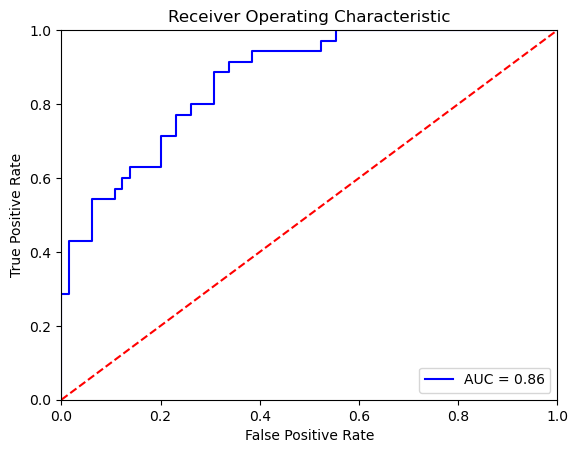

In [43]:
# Hyperparameter tuning

logreg = linear_model.LogisticRegression(C=1,solver='lbfgs', multi_class='auto')

logreg.fit(X_train,y_train)

y_pred = logreg.predict(X_test)

print(classification_report(y_test,y_pred))

print(accuracy_score(y_test,y_pred)*100)

print(confusion_matrix(y_test,y_pred))


import sklearn.metrics as metrics
# calculate the fpr and tpr for all thresholds of the classification
probs = logreg.predict_proba(X_test)
preds = probs[:,1]
fpr, tpr, threshold = metrics.roc_curve(y_test, preds)
roc_auc = metrics.auc(fpr, tpr)

# method I: plt
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

### Feature engineering
**TAAK: Creeër hogere orde features door gebruik te maken van *preprocessing.PolynomialFeatures*.** 

Deze functie zal automatische hogere orde features aanmaken door het combineren van de aanwezige features. Heb je bijvoorbeeld drie features, zijnde A, B en C dan worden bij de keuze van een derde orde PolynomialFeatures volgende nieuwe features bijgemaakt:
$A^3, B^3,C^3,A^2B,A^2C,AB^2, B^2C,...$

Experimenteer met verschillende ordes en gebruik de regularisatieparameter C om de performantie te verhogen.

**Opgepast**: het kiezen van een te hoge orde zorgt voor een exponentiële toename aan features waardoor de logistic regression classifier niet meer binnen aanvaardbare tijd getraind kan worden. Advies is om niet hoger te gaan dan 4de orde.

dimensie van X_train_poly:  (292, 45)
dimensie van X_test_poly:  (100, 45)
              precision    recall  f1-score   support

           0       0.78      0.94      0.85        65
           1       0.82      0.51      0.63        35

    accuracy                           0.79       100
   macro avg       0.80      0.73      0.74       100
weighted avg       0.79      0.79      0.78       100

[[61  4]
 [17 18]]
accuracy op de test set: 79.0
accuracy op de training set: 80.82191780821918


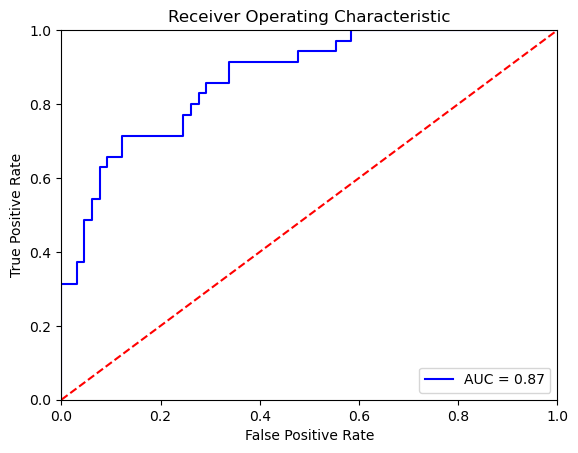

coefficienten: 

[[-0.45106179  0.          0.93674005  0.          0.15491003  0.
   0.15772694  0.21650834  0.35735266  0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
  -0.05212605  0.          0.          0.          0.         -0.0369004
   0.         -0.11434026  0.11132747  0.          0.          0.
   0.          0.         -0.1276279 ]]


In [44]:
# Toevoegen van extra features

# Aanmaken van de hogere orde features
graad = 2

poly = PolynomialFeatures(graad)
poly.fit(X_train)
X_train_poly = poly.transform(X_train)
X_test_poly = poly.transform(X_test)
print('dimensie van X_train_poly: ',X_train_poly.shape)
print('dimensie van X_test_poly: ',X_test_poly.shape)

logreg_poly = linear_model.LogisticRegression(C=0.1,solver='liblinear',multi_class='auto',penalty='l1')

logreg_poly.fit(X_train_poly,y_train)

y_pred_poly = logreg_poly.predict(X_test_poly)

print(classification_report(y_test,y_pred_poly))

print(confusion_matrix(y_test,y_pred_poly))

print('accuracy op de test set:', accuracy_score(y_test,y_pred_poly)*100)

print('accuracy op de training set:', accuracy_score(y_train,logreg_poly.predict(X_train_poly))*100)



import sklearn.metrics as metrics
# calculate the fpr and tpr for all thresholds of the classification
probs = logreg_poly.predict_proba(X_test_poly)
preds = probs[:,1]
fpr, tpr, threshold = metrics.roc_curve(y_test, preds)
roc_auc = metrics.auc(fpr, tpr)

# method I: plt
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()


print('coefficienten: \n')
print(logreg_poly.coef_)

**TAAK: Wat zijn de bevindingen? Formuleer een conclusie.** <p>Bespreek hierin de performantie van de getrainde modellen. Wat is de invloed van de parameter C en van het aantal features? Heb je te maken gehad met underfitting en overfitting en hoe heb je dit bepaald? Welke accuracy werd bekomen en hoe zit het met de Recall en Precision? Is de grootte van de trainingset voldoende?</p>

**Conclusie:** Hoe hoger de graad van het polynoom, des te hoger de kans op overfitting. 
Dit kan je testen zien aan het feit dat de accuracy op de trainig set hoog is maar beduidend lager op de test set. Ook hier lijkt L1 regularisatie het best te scoren.

**TAAK: Voorspel aan de hand van het getrainde model**

Voorspel of iemand met onderstaande medische parameters als dan niet diabetes heeft. Geef ook de zekerheid van het model weer (kansen dat de patiënt tot een bepaalde klasse behoort).

Pregnancies: 2 -
Glucose: 132 -
BloodPressure: 74 - 
SkinThickness: 20 - 
Insulin: 21 - 
BMI: 24.3 - 
DiabetesPedigreeFunction: 128 - 
Age: 37

In [45]:
patient = np.array([[2, 132, 74, 20, 21, 24.3, 1.28, 37]])
patient_poly = poly.transform(patient)

scaler = preprocessing.StandardScaler().fit(X_train_poly)
patient_poly = scaler.transform(patient_poly)

y_patient_poly = logreg_poly.predict(patient_poly)
y_patient_poly_prob = logreg_poly.predict_proba(patient_poly)

print(patient)
print(y_patient_poly_prob)

[[  2.   132.    74.    20.    21.    24.3    1.28  37.  ]]
[[0. 1.]]


## Opdracht 3: Kankerdetectie

**TAAK: Train een model om te voorspellen of een bepaalde tumor goedaardig (benign) of kwaadaardig (malignant) is.**
Gebruik daarvoor de dataset '*cancer.csv*'

Baseer je op de methodieken uit voorgaande opdrachten om tot een zo goed mogelijk resultaat te komen. 
**Bespreek** telkens de gemaakte keuzes en resultaten en kom tot een duidelijk besluit.

Tip: een classifier kan enkel maar getraind worden met numerieke waarden. Vervang daarom bij de feature diagnose de twee klasses die voorkomen door 0 en 1, waarbij 0 staat voor goedaardig en 1 voor kwaadaardig.


In [46]:
dataset = pd.read_csv('../DATA/cancer.csv')
dataset['diagnosis'].replace(['M', 'B'], [1, 0], inplace=True)
dataset.head(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,0.08902,NaN
1,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758,NaN
2,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300,NaN
3,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.16250,0.2364,0.07678,NaN
4,843786,1,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440,NaN
5,844359,1,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368,NaN
6,84458202,1,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510,NaN
7,844981,1,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.20600,0.4378,0.10720,NaN
8,84501001,1,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750,NaN
9,845636,1,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,...,33.88,123.80,1150.0,0.1181,0.1551,0.1459,0.09975,0.2948,0.08452,NaN


In [47]:
klasses = dataset.diagnosis.unique()
print(klasses)

[1 0]


In [48]:
g = dataset.groupby('diagnosis')
g.diagnosis.count()

diagnosis
0    357
1    211
Name: diagnosis, dtype: int64

In [49]:
# Verwijeren van de id kolom
dataset.drop(['id'],axis=1,inplace=True)

# verwijderen van de laatste kolom
dataset.drop(dataset.columns[-1], axis=1, inplace=True)
dataset.head()

y = dataset['diagnosis'].values
X = dataset.drop(['diagnosis'],axis=1)

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=0)

print(X_test.shape)

# Om conversion warning te vermijden:

X_train = X_train.astype('float64')
X_test = X_test.astype('float64')

# Scaling

scaler = preprocessing.StandardScaler().fit(X_train)


X_train = scaler.transform((X_train))
X_test = scaler.transform(X_test)

print(X_train.shape)


(228, 30)
(340, 30)


              precision    recall  f1-score   support

           0       0.97      1.00      0.99       142
           1       1.00      0.95      0.98        86

    accuracy                           0.98       228
   macro avg       0.99      0.98      0.98       228
weighted avg       0.98      0.98      0.98       228

98.24561403508771
[[142   0]
 [  4  82]]


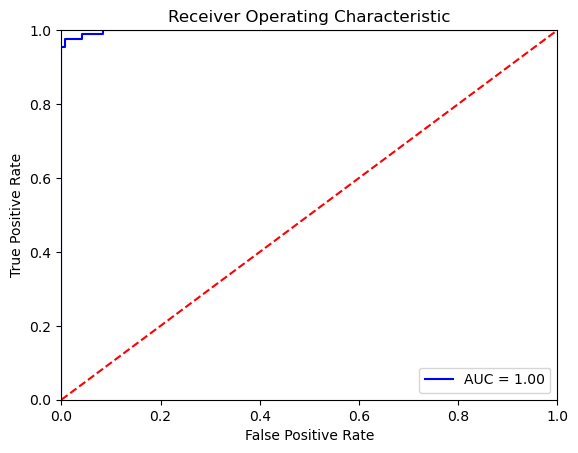

In [51]:
logreg = linear_model.LogisticRegression(C=0.5,solver='liblinear')
logreg.fit(X_train,y_train)

y_pred = logreg.predict(X_test)

print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred) * 100)

#Kolom : voorspeld Rij : actueel
print(confusion_matrix(y_test,y_pred))

import sklearn.metrics as metrics
# calculate the fpr and tpr for all thresholds of the classification
probs = logreg.predict_proba(X_test)
preds = probs[:,1]
fpr, tpr, threshold = metrics.roc_curve(y_test, preds)
roc_auc = metrics.auc(fpr, tpr)

# method I: plt
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [52]:
# Toevoegen van extra features

# Aanmaken van de hogere orde features
graad = 3

poly = PolynomialFeatures(graad)
poly.fit(X_train)
X_train_poly = poly.transform(X_train)
X_test_poly = poly.transform(X_test)
print('dimensie van X_train_poly: ',X_train_poly.shape)
print('dimensie van X_test_poly: ',X_test_poly.shape)

logreg_poly = linear_model.LogisticRegression(C=1,solver='liblinear')

logreg_poly.fit(X_train_poly,y_train)

y_pred_poly = logreg_poly.predict(X_test_poly)

print(classification_report(y_test,y_pred_poly))

print(accuracy_score(y_test,y_pred_poly)*100)

print(confusion_matrix(y_test,y_pred_poly))

dimensie van X_train_poly:  (340, 5456)
dimensie van X_test_poly:  (228, 5456)
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       142
           1       1.00      0.93      0.96        86

    accuracy                           0.97       228
   macro avg       0.98      0.97      0.97       228
weighted avg       0.97      0.97      0.97       228

97.36842105263158
[[142   0]
 [  6  80]]


**TAAK: Voorspel of een gezwel met onderstaande parameters goedaardig of kwaadaardig is.**

radius_mean: 17.99 |
texture_mean: 10.38 |
perimeter_mean: 122.8 |
area_mean: 1001 |
smoothness_mean: 0.1184 |
compactness_mean: 0.2776 |
concavity_mean: 0.3001 |
concave points_mean: 0.1471 |
symmetry_mean: 0.2419 |
fractal_dimension_mean: 0.07871 |
radius_se: 1.095 |
texture_se: 0.9053 |
perimeter_se: 8.589 |
area_se:153.4 |
smoothness_se:0.006399 |
compactness_se: 0.04904 |
concavity_se: 0.05373 |
concave points_se: 0.01587 |
symmetry_se: 0.03003 |
fractal_dimension_se: 0.006193 |
radius_worst: 25.38 |
texture_worst: 17.33 |
perimeter_worst: 184.6 |
area_worst: 2019 |
smoothness_worst: 0.1622 |
compactness_worst: 0.6656 |
concavity_worst: 0.7119 |
concave points_worst: 0.2654 |
symmetry_worst: 0.4601 |
fractal_dimension_worst: 0.1189 |

In [53]:
cancer = np.array([[17.99, 10.38, 122.8, 1001, 0.1184, 0.2776, 0.3001, 0.1471, 0.2419, 0.07871, 1.095, 0.9053, 8.589, 153.4, 0.006399, 0.04904, 0.05373, 0.01587, 0.03003, 0.006193, 25.38, 17.33, 184.6, 2019, 0.1622, 0.6656, 0.7119, 0.2654, 0.4601, 0.1189]])

y_cancer = logreg.predict(cancer)
y_cancer_prob = logreg.predict_proba(cancer)

print(y_cancer)
print(y_cancer_prob)

[1]
[[0. 1.]]
